# 01 · Kaggle dataset acquisition

## Purpose

Acquire the specified competition files through the official Kaggle CLI, or deliberately use a CSV already imported in Manual mode.

## Method

Check CLI access and competition file names before download. Download, safely extract, validate train/test/submission roles, fingerprint the files, and select the training file. No other dataset is substituted.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

This step requires a Kaggle account with competition access. If access fails, authenticate locally with kaggle auth login or select Manual mode; do not share tokens.

## References

Official CLI: https://github.com/Kaggle/kaggle-cli · Competition: https://www.kaggle.com/competitions/retail-return-risk-modeling


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '01 · Kaggle dataset acquisition')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 01 · Kaggle dataset acquisition


Using the hash-verified Kaggle dataset cache (checked within the last 7 days).
Acquisition metadata:


competition                                       retail-return-risk-modeling
dataset_version                                              2ae5e87906198d2e
fingerprint_sha256          2ae5e87906198d2e3688c12bd807b33194115aea579aac...
file_sha256                 {'train.csv': '1d44901b7a1f1aaacb5a899909c31b6...
file_bytes                  {'train.csv': 33115892, 'test.csv': 8180207, '...
file_mtime_ns               {'train.csv': 1773916038000000000, 'test.csv':...
listing_file_bytes          {'sample_submission.csv': 478039, 'test.csv': ...
listing_creation_dates      {'sample_submission.csv': '2026-03-19T17:27:13...
listing_names                    [train.csv, test.csv, sample_submission.csv]
validated_existing_cache                                                 True
acquisition_mode                        verified_preexisting_kaggle_csv_cache
cache_validated_at                                  2026-11-15T06:04:28+00:00
last_checked_at                                     2026-11-15T0

,file,bytes
0,train.csv,33115892
1,test.csv,8180207
2,sample_submission.csv,478039


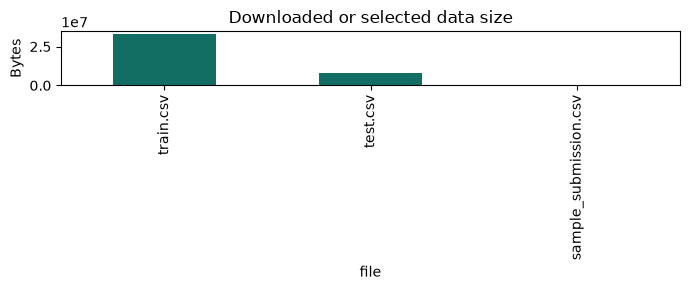

In [2]:
from returnwise.data.kaggle import sync_competition
from returnwise.storage import load_active_dataset, use_kaggle_training_data
import matplotlib.pyplot as plt
import pandas as pd

USE_MANUAL_DATASET = False  # Change to True only after importing a CSV in the application.
if USE_MANUAL_DATASET:
    frame, manifest = load_active_dataset()
    if frame is None:
        raise RuntimeError('No active manual CSV. Import a CSV in the app, then rerun this notebook.')
    print('Explicit manual dataset selected:', manifest)
else:
    acquisition = sync_competition(force=False)
    print(acquisition.message)
    if acquisition.details:
        print(acquisition.details)
    if not acquisition.ok:
        raise RuntimeError('Kaggle acquisition stopped safely. Authenticate and verify access, or explicitly select a manual dataset.')
    manifest = use_kaggle_training_data()
    frame = None  # Avoid rereading the training CSV; only the manifest is needed below.
    print('Acquisition metadata:')
    display(pd.Series(acquisition.metadata or {}))

if acquisition.ok if not USE_MANUAL_DATASET else True:
    sizes = acquisition.metadata.get('file_bytes', {}) if not USE_MANUAL_DATASET else {'imported CSV': frame.memory_usage(deep=True).sum()}
    size_frame = pd.DataFrame({'file': list(sizes), 'bytes': list(sizes.values())})
    display(size_frame)
    ax = size_frame.set_index('file')['bytes'].plot.bar(figsize=(7, 3), color='#126E63', title='Downloaded or selected data size')
    ax.set_ylabel('Bytes')
    plt.tight_layout()
    plt.show()
from returnwise.experiments import log_experiment
log_experiment('Dataset acquisition', None, {'success': bool(not USE_MANUAL_DATASET and acquisition.ok) if not USE_MANUAL_DATASET else True},
               {'source': 'manual' if USE_MANUAL_DATASET else 'kaggle', 'metadata': acquisition.metadata if not USE_MANUAL_DATASET else manifest})
from returnwise.storage import active_dataset_fingerprint
fingerprint = active_dataset_fingerprint()
experiment_mode = state.get('experiment_mode', 'quick')
if state.get('dataset_fingerprint') != fingerprint:
    state = {'experiment_mode': experiment_mode}
state['dataset_fingerprint'] = fingerprint
state['dataset_manifest'] = manifest
save_state(state)
